In [1]:
from ultralytics import YOLO
import cv2
from collections import Counter
import matplotlib.pyplot as plt


In [2]:
model_path='yolov8m.pt'

In [3]:
def process_image(image_path, model_path, output_resolution=(640, 480)):
    """
    Detect objects in an image, count classes, and display the annotated image.
    """
    # Load the YOLO model
    model = YOLO(model_path)

    # Load and resize the image
    image = cv2.imread(image_path)
    image_resized = cv2.resize(image, output_resolution)

    # Run detection
    results = model.predict(image_resized, conf=0.5)

    # Count detected classes
    detected_classes = [model.names[int(cls)] for cls in results[0].boxes.cls]
    class_counts = Counter(detected_classes)

    # Annotate image
    annotated_image = results[0].plot()
    start_x, start_y = 10, 30
    for i, (cls, count) in enumerate(class_counts.items()):
        text = f"{cls} = {count}"
        position = (start_x, start_y + i * 20)
        cv2.putText(
            annotated_image, text, position,
            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2, cv2.LINE_AA
        )

    # Display annotated image
    plt.figure(figsize=(10, 10))
    plt.imshow(cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB))
    plt.axis('off')
    plt.show()

    return class_counts


In [4]:
def process_video(video_path, output_path, model_path, output_resolution=(640, 480)):
    """
    Detect objects in a video, count classes, and save the annotated video.
    """
    # Load the YOLO model
    model = YOLO(model_path)

    # Load the video
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        print("Error: Could not open video.")
        return

    # Define output video writer
    frame_width, frame_height = output_resolution
    fps = int(cap.get(cv2.CAP_PROP_FPS))
    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    out = cv2.VideoWriter(output_path, fourcc, fps, (frame_width, frame_height))

    while True:
        ret, frame = cap.read()
        if not ret:
            break

        # Resize frame
        frame_resized = cv2.resize(frame, (frame_width, frame_height))

        # Run detection
        results = model.predict(frame_resized, conf=0.5)

        # Count detected classes
        detected_classes = [model.names[int(cls)] for cls in results[0].boxes.cls]
        class_counts = Counter(detected_classes)

        # Annotate frame
        annotated_frame = results[0].plot()
        start_x, start_y = 10, 30
        for i, (cls, count) in enumerate(class_counts.items()):
            text = f"{cls} = {count}"
            position = (start_x, start_y + i * 20)
            cv2.putText(
                annotated_frame, text, position,
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2, cv2.LINE_AA
            )

        # Write frame to output video
        out.write(annotated_frame)

        # Optionally display the frame
        cv2.imshow('YOLOv8 Detection', annotated_frame)
        if cv2.waitKey(1) & 0xFF == ord('q'):  # Press 'q' to quit early
            break

    # Release resources
    cap.release()
    out.release()
    cv2.destroyAllWindows()
    print("Video processing complete. Saved to:", output_path)




0: 480x640 10 persons, 9 ties, 3 chairs, 1258.2ms
Speed: 15.6ms preprocess, 1258.2ms inference, 15.6ms postprocess per image at shape (1, 3, 480, 640)


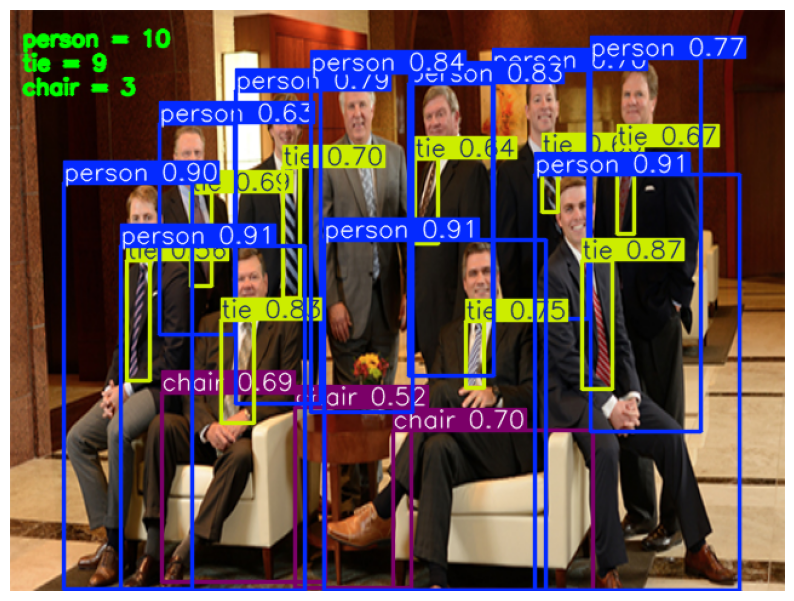

Image Class Counts: Counter({'person': 10, 'tie': 9, 'chair': 3})


In [5]:
image_counts = process_image('obj.jpg', model_path, output_resolution=(640, 480))
print("Image Class Counts:", image_counts)


0: 480x640 8 cars, 1 truck, 1129.3ms
Speed: 0.0ms preprocess, 1129.3ms inference, 15.6ms postprocess per image at shape (1, 3, 480, 640)


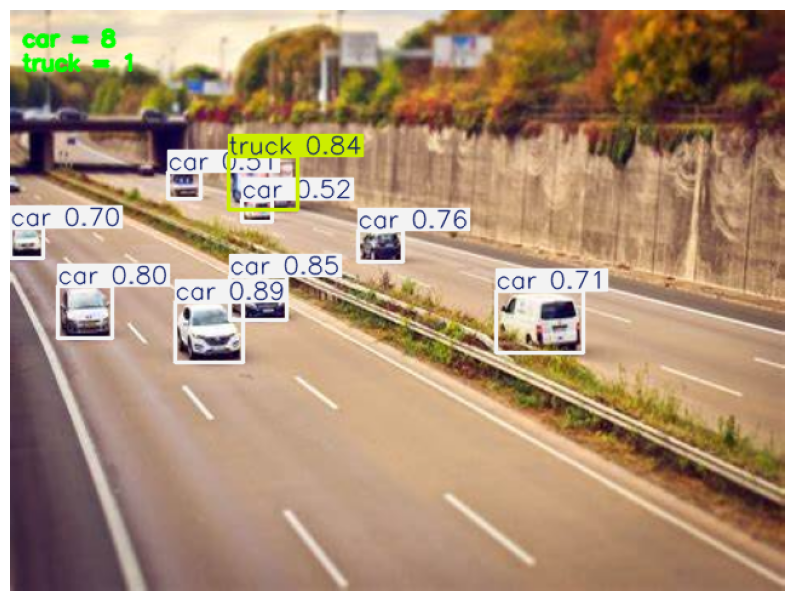

Image Class Counts: Counter({'car': 8, 'truck': 1})


In [6]:
image_counts = process_image('OIP.jpeg', model_path, output_resolution=(640, 480))
print("Image Class Counts:", image_counts)


0: 480x640 4 dogs, 1168.2ms
Speed: 0.0ms preprocess, 1168.2ms inference, 15.6ms postprocess per image at shape (1, 3, 480, 640)


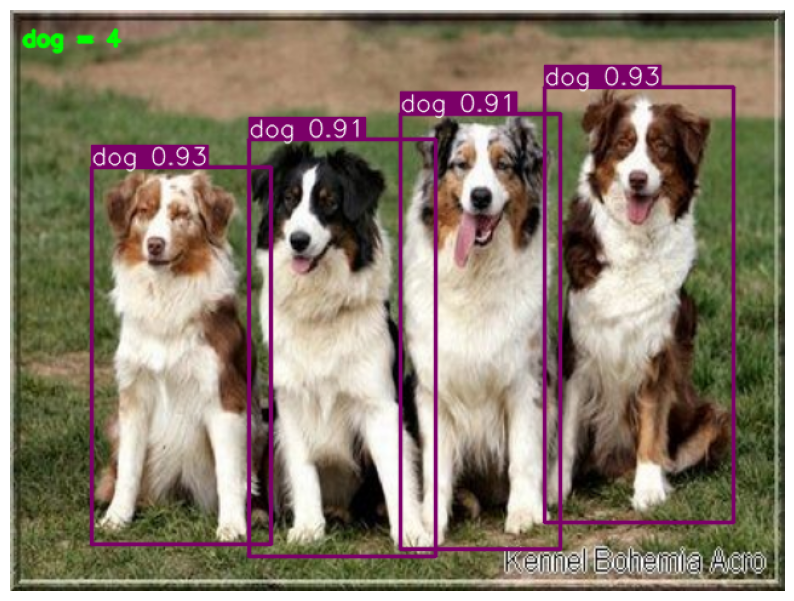

Image Class Counts: Counter({'dog': 4})


In [7]:
image_counts = process_image('dogs.jpg', model_path, output_resolution=(640, 480))
print("Image Class Counts:", image_counts)

For Video Testing

In [11]:
process_video(
        video_path=r'C:\Users\Muhammad Haroon\Downloads\counting.mp4',
        output_path='output_video.mp4',
        model_path='yolov8n.pt',
        output_resolution=(640, 480)
    )



0: 480x640 1 person, 1 car, 256.2ms
Speed: 8.0ms preprocess, 256.2ms inference, 0.0ms postprocess per image at shape (1, 3, 480, 640)

0: 480x640 2 persons, 1 car, 319.3ms
Speed: 6.0ms preprocess, 319.3ms inference, 3.5ms postprocess per image at shape (1, 3, 480, 640)

0: 480x640 1 car, 368.5ms
Speed: 12.2ms preprocess, 368.5ms inference, 4.0ms postprocess per image at shape (1, 3, 480, 640)

0: 480x640 2 persons, 1 car, 260.2ms
Speed: 5.2ms preprocess, 260.2ms inference, 0.0ms postprocess per image at shape (1, 3, 480, 640)

0: 480x640 2 persons, 1 car, 243.4ms
Speed: 4.7ms preprocess, 243.4ms inference, 0.0ms postprocess per image at shape (1, 3, 480, 640)

0: 480x640 2 persons, 1 car, 264.7ms
Speed: 4.0ms preprocess, 264.7ms inference, 0.0ms postprocess per image at shape (1, 3, 480, 640)

0: 480x640 2 persons, 1 car, 255.6ms
Speed: 18.0ms preprocess, 255.6ms inference, 0.0ms postprocess per image at shape (1, 3, 480, 640)

0: 480x640 2 persons, 1 car, 236.6ms
Speed: 20.2ms prepro

In [12]:
def detect_and_annotate(frame, model):
    """
    Detect objects in a frame and annotate it with class counts.
    """
    # Run detection
    results = model.predict(frame, conf=0.5)

    # Count detected classes
    detected_classes = [model.names[int(cls)] for cls in results[0].boxes.cls]
    class_counts = Counter(detected_classes)

    # Annotate frame
    annotated_frame = results[0].plot()
    start_x, start_y = 10, 30
    for i, (cls, count) in enumerate(class_counts.items()):
        text = f"{cls} = {count}"
        position = (start_x, start_y + i * 20)
        cv2.putText(
            annotated_frame, text, position,
            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2, cv2.LINE_AA
        )

    return annotated_frame

In [13]:
def process_video_for_testing(video_path, model_path='yolov8n.pt', output_resolution=(640, 480)):
    """
    Process a video for testing (viewing only, without saving).
    """
    # Load the YOLO model
    model = YOLO(model_path)

    # Load the video
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        print("Error: Could not open video.")
        return

    while True:
        ret, frame = cap.read()
        if not ret:
            break

        # Resize frame
        frame_resized = cv2.resize(frame, output_resolution)

        # Detect and annotate
        annotated_frame = detect_and_annotate(frame_resized, model)

        # Display the annotated frame
        cv2.imshow('YOLOv8 Detection (Testing)', annotated_frame)
        if cv2.waitKey(1) & 0xFF == ord('q'):  # Press 'q' to quit early
            break

    # Release resources
    cap.release()
    cv2.destroyAllWindows()
    print("Testing complete.")


In [14]:
def process_video_for_saving(video_path, output_path, model_path, output_resolution=(640, 480)):
    """
    Process a video for saving the annotated output.
    """
    # Load the YOLO model
    model = YOLO(model_path)

    # Load the video
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        print("Error: Could not open video.")
        return

    # Define output video writer
    frame_width, frame_height = output_resolution
    fps = int(cap.get(cv2.CAP_PROP_FPS))
    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    out = cv2.VideoWriter(output_path, fourcc, fps, (frame_width, frame_height))

    while True:
        ret, frame = cap.read()
        if not ret:
            break

        # Resize frame
        frame_resized = cv2.resize(frame, (frame_width, frame_height))

        # Detect and annotate
        annotated_frame = detect_and_annotate(frame_resized, model)

        # Write frame to output video
        out.write(annotated_frame)

    # Release resources
    cap.release()
    out.release()
    print("Video processing complete. Saved to:", output_path)




In [15]:

# For testing video without saving
process_video_for_testing(
video_path = 'path/to/video.mp4',
model_path = model_path,
output_resolution = (640, 480)
)

# For saving annotated video
process_video_for_saving(
video_path='path/to/video.mp4',
output_path='output_video.mp4',
model_path='yolov8n.pt',
output_resolution=(640, 480)
)


Error: Could not open video.
Error: Could not open video.


In [17]:
import cv2
from ultralytics import YOLO
from collections import Counter

def process_video(video_path, output_path, model_path):
    """
    Detect objects in a video, count classes, and save the annotated video
    while maintaining the original video resolution.
    """
    # Load the YOLO model
    model = YOLO(model_path)

    # Load the video
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        print("Error: Could not open video.")
        return

    # Get the original video resolution
    frame_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    frame_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = int(cap.get(cv2.CAP_PROP_FPS))

    # Define output video writer
    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    out = cv2.VideoWriter(output_path, fourcc, fps, (frame_width, frame_height))

    while True:
        ret, frame = cap.read()
        if not ret:
            break

        # Run detection
        results = model.predict(frame, conf=0.5)

        # Count detected classes
        detected_classes = [model.names[int(cls)] for cls in results[0].boxes.cls]
        class_counts = Counter(detected_classes)

        # Annotate frame
        annotated_frame = results[0].plot()
        start_x, start_y = 10, 30
        for i, (cls, count) in enumerate(class_counts.items()):
            text = f"{cls} = {count}"
            position = (start_x, start_y + i * 20)
            cv2.putText(
                annotated_frame, text, position,
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2, cv2.LINE_AA
            )

        # Write frame to output video
        out.write(annotated_frame)

        # Optionally display the frame
        cv2.imshow('YOLOv8 Detection', annotated_frame)
        if cv2.waitKey(1) & 0xFF == ord('q'):  # Press 'q' to quit early
            break

    # Release resources
    cap.release()
    out.release()
    cv2.destroyAllWindows()
    print("Video processing complete. Saved to:", output_path)


In [19]:
process_video(
        video_path=r'C:\Users\Muhammad Haroon\Downloads\counting.mp4',
        output_path='output_video.mp4',
        model_path='yolov8n.pt',
        # output_resolution=(640, 480)
    )



0: 640x352 2 persons, 1 truck, 221.6ms
Speed: 6.5ms preprocess, 221.6ms inference, 0.0ms postprocess per image at shape (1, 3, 640, 352)

0: 640x352 2 persons, 1 truck, 259.9ms
Speed: 16.0ms preprocess, 259.9ms inference, 0.0ms postprocess per image at shape (1, 3, 640, 352)

0: 640x352 4 persons, 1 truck, 267.4ms
Speed: 14.2ms preprocess, 267.4ms inference, 0.0ms postprocess per image at shape (1, 3, 640, 352)

0: 640x352 4 persons, 1 car, 1 truck, 217.2ms
Speed: 13.3ms preprocess, 217.2ms inference, 0.0ms postprocess per image at shape (1, 3, 640, 352)

0: 640x352 4 persons, 1 truck, 206.1ms
Speed: 0.4ms preprocess, 206.1ms inference, 0.0ms postprocess per image at shape (1, 3, 640, 352)

0: 640x352 5 persons, 1 truck, 222.9ms
Speed: 0.2ms preprocess, 222.9ms inference, 0.0ms postprocess per image at shape (1, 3, 640, 352)

0: 640x352 4 persons, 1 car, 1 truck, 218.2ms
Speed: 1.8ms preprocess, 218.2ms inference, 0.0ms postprocess per image at shape (1, 3, 640, 352)

0: 640x352 4 per